# Where the Model Fails: final V6 and V22

**Final models are fixed:** off-market **V6**; list-aware **V22**. This notebook evaluates those models, not the starter or the July V7 experiments. `models.make_model()` and `python run.py validate/predict` use the same choices.

**Run All works on its own.** It loads only labelled historical listings, generates missing monthly walk-forward predictions for December 2025-May 2026, and reuses a source/data-verified cache on later runs. First execution trains both models for each month; there is no new parameter search. Results and PNG/SVG graphics go to `outputs/where_model_fails/final_v6_v22/`.

The story: **How often do estimates fail? Which homes are affected? Does V22 improve on asking price? Can failure be recognised before sale? What uncertainty remains?**

Rubric: error analysis 20 points, performance honesty 10 points; finale risks/limits 20 points. Sources: local `rubric.md` and `handout.md`.

## 1. Setup and fixed model choices

V6 uses a 12-month comparable-price anchor, a hard-30 community fallback, extra condition phrases, and a full recent level correction. V22 learns the log sold-to-list gap using the community category, historical peer ask, recent discounts, and listing-month factor. Both retain 127 leaves, learning rate 0.03, and 700 trees from the saved notebook choices.

These settings are fixed before this failure analysis. Earlier model selection has already used the validation period, so these are exploratory validation results, not a fresh independent test. Missing/unparseable positive area is raised explicitly rather than silently producing an invalid valuation.

In [13]:
from pathlib import Path
import sys, os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if 'DATA_DIR' not in os.environ and (ROOT/'data/listings.parquet').exists():
    os.environ['DATA_DIR'] = str(ROOT/'data')
import data
from features import square_feet
from final_validation import final_predictions, FINAL_MODELS
from failure_visuals import overview, failure_segments, warning_dashboard, v22_paired_analysis, paired_columns, subgroup_table
OUT = ROOT / 'outputs/where_model_fails/final_v6_v22'
OUT.mkdir(parents=True, exist_ok=True)
MIN_N, FAIL_PCT, SEVERE_PCT, SEED = 50, 20.0, 30.0, 42
FORCE_REBUILD = False
print('Final model choices:', FINAL_MODELS)
print('Output:', OUT)

Final model choices: {'off_market': 'V6', 'list_aware': 'V22'}
Output: C:\Users\Elowe\OneDrive\Desktop\SSU-Data-Dash\outputs\where_model_fails\final_v6_v22


## 2. Generate real V6/V22 predictions and audit their provenance

Each sale month is predicted using only sales closed before that month. V6's bias calibration uses the preceding three months; V22's feature tables and community categories are rebuilt from that month's training sales. V22's actual feature-support diagnostics are saved alongside its predictions. Baselines use the exact same homes: recent community/type price-per-square-foot anchor for V6, asking price for V22.

Rows are joined by home ID, not by position across files. We check target agreement, duplicate IDs, positive finite prices and the training cutoff. A source/data fingerprint prevents stale predictions being silently reused after a model change. No submission or hidden-test prices enter this analysis.

In [14]:
listings = data.load('listings').copy()
assert not listings['ml_num'].duplicated().any()
assert listings['date_sold'].max() < pd.Timestamp('2026-06-01')
pred = final_predictions(listings, force=FORCE_REBUILD)
assert set(pred['model']) == {'V6', 'V22'}
assert pred.loc[pred.track.eq('off_market'),'model'].eq('V6').all()
assert pred.loc[pred.track.eq('list_aware'),'model'].eq('V22').all()
pred['source'] = 'Source/data-verified final_models cache'
KEYS = ['track','model','protocol','source']
assert not pred.duplicated(KEYS+['ml_num']).any()
for col in ['sold_price','predicted_price','baseline_price']:
    assert np.isfinite(pred[col]).all() and pred[col].gt(0).all(), col
pred['fit_cutoff'] = pd.to_datetime(pred['fit_cutoff'])
meta_cols = ['ml_num','sold_price','date_sold','date_listed','house_type_name','community',
             'municipality','house_area','list_price','bedrooms','washrooms','latitude','longitude','remarks']
meta = listings[meta_cols].rename(columns={'sold_price':'actual_price'})
df = pred.drop(columns=['house_type_name','month'],errors='ignore').merge(meta,on='ml_num',how='left',validate='many_to_one',indicator=True)
assert df['_merge'].eq('both').all()
assert np.allclose(df.sold_price,df.actual_price,rtol=0,atol=.01)
assert df.date_sold.ge(df.fit_cutoff).all()
df['month'] = df.date_sold.dt.strftime('%Y-%m')
df['horizon'] = (df.date_sold.dt.year-df.fit_cutoff.dt.year)*12+df.date_sold.dt.month-df.fit_cutoff.dt.month+1
df['signed_pct'] = 100*(df.predicted_price/df.sold_price-1)
df['ape'] = df.signed_pct.abs()
df['dollar_error'] = (df.predicted_price-df.sold_price).abs()
df['large_error'] = df.ape.gt(FAIL_PCT)
df['square_feet'] = square_feet(df.house_area)
df['price_band'] = pd.cut(df.sold_price,[0,500000,750000,1000000,1500000,2000000,np.inf],
    labels=['<500k','500-750k','750k-1m','1-1.5m','1.5-2m','2m+'],right=False)
df['listed_before_fit'] = df.date_listed.lt(df.fit_cutoff)
df = paired_columns(df)
provenance=df.groupby(KEYS).agg(n=('ml_num','size'),start=('date_sold','min'),end=('date_sold','max'),
    cutoff_min=('fit_cutoff','min'),cutoff_max=('fit_cutoff','max'),listed_before_fit_rate=('listed_before_fit','mean')).reset_index()
display(provenance)
provenance.to_csv(OUT/'provenance.csv',index=False)

Using verified V6/V22 cache: C:\Users\Elowe\OneDrive\Desktop\SSU-Data-Dash\outputs\final_models\monthly_walk_forward_2025-12_2026-05.csv


,track,model,protocol,source,n,start,end,cutoff_min,cutoff_max,listed_before_fit_rate
0,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,10069,2025-12-01,2026-05-31,2025-12-01,2026-05-01,0.64207
1,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,10069,2025-12-01,2026-05-31,2025-12-01,2026-05-01,0.64207


## 3. Metrics: typical errors, large misses and bias

**MdAPE** describes a typical percentage miss; **MAPE** is more affected by large misses; **P90 APE** means 10% of homes have worse errors. The >20% and >30% shares are declared material-error thresholds, not competition rules. Positive signed error means overvaluation; negative means undervaluation. Dollar error describes financial magnitude.

Compare each model to its own baseline on the same homes. Do not interpret off-market versus list-aware differences as a fair contest: asking price is extra information that only V22 may use. Groups with fewer than 50 homes are retained in CSVs but should not support strong conclusions.

In [15]:
def metrics(g):
    return pd.Series({'n': len(g), 'MdAPE': g['ape'].median(), 'MAPE': g['ape'].mean(),
        'P90_APE': g['ape'].quantile(.9), 'over_20_pct': 100*g['ape'].gt(FAIL_PCT).mean(),
        'over_30_pct': 100*g['ape'].gt(SEVERE_PCT).mean(),
        'median_signed_pct': g['signed_pct'].median(),
        'median_abs_dollars': g['dollar_error'].median(), 'small_sample': len(g)<MIN_N})
def summarize(frame, groups):
    rows = []
    for key, g in frame.groupby(groups, observed=True, dropna=False, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(groups, key)), **metrics(g).to_dict()})
    return pd.DataFrame(rows)
overall = summarize(df, KEYS)
display(overall.round(2))
overall.to_csv(OUT / 'overall.csv', index=False)

,track,model,protocol,source,n,MdAPE,MAPE,P90_APE,over_20_pct,over_30_pct,median_signed_pct,median_abs_dollars,small_sample
0,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,10069,8.56,10.88,22.58,13.58,4.20,-1.23,64716.71,False
1,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,10069,4.28,5.37,11.33,1.21,0.03,0.90,32255.95,False


In [16]:
comparison=[]
for track,g in df.groupby('track'):
    comparison.append({'track':track,'model':g.model.iloc[0],'n':len(g),
        'model_MdAPE':g.ape.median(),'baseline_MdAPE':g.baseline_ape.median(),
        'model_MAPE':g.ape.mean(),'baseline_MAPE':g.baseline_ape.mean(),
        'mean_APE_reduction_pp':g.gain_pp.mean(),'model_closer_pct':100*g.gain_pp.gt(1e-8).mean()})
comparison=pd.DataFrame(comparison)
display(comparison.round(2));comparison.to_csv(OUT/'paired_baseline_summary.csv',index=False)

,track,model,n,model_MdAPE,baseline_MdAPE,model_MAPE,baseline_MAPE,mean_APE_reduction_pp,model_closer_pct
0,list_aware,V22,10069,4.28,7.26,5.37,8.09,2.72,69.77
1,off_market,V6,10069,8.56,15.33,10.88,20.32,9.44,71.69


## 4. Both tracks: an overview you can read at a glance

Each model gets its own four-panel dashboard, always compared with its baseline on the same homes.

1. **Error curve:** further up/left means more homes are close to the true price; the 20% line makes material misses visible.
2. **Monthly accuracy:** shows whether a pooled score conceals weaker months.
3. **Error bands:** turns percentages into the share of homes experiencing small, moderate or large misses.
4. **Predicted versus actual price:** density avoids thousands of overlapping dots. Above the diagonal is overvaluation; below it is undervaluation. Prices use logarithmic axes.

The title gives the model name, sample count, typical and mean error, large-error rate and bias. PNG and SVG versions are exported for the report.

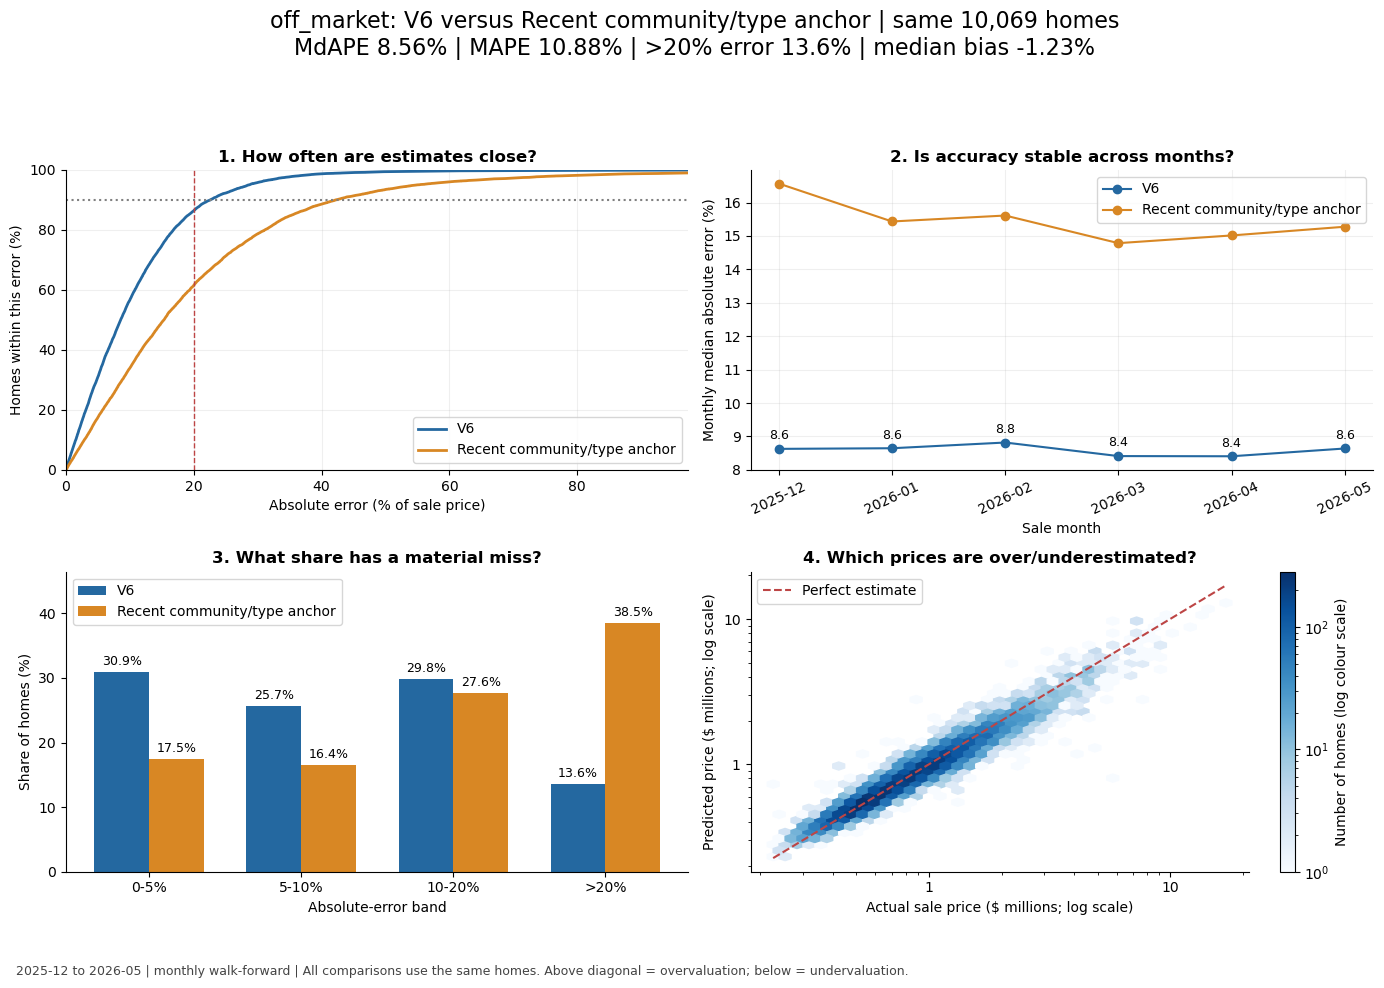

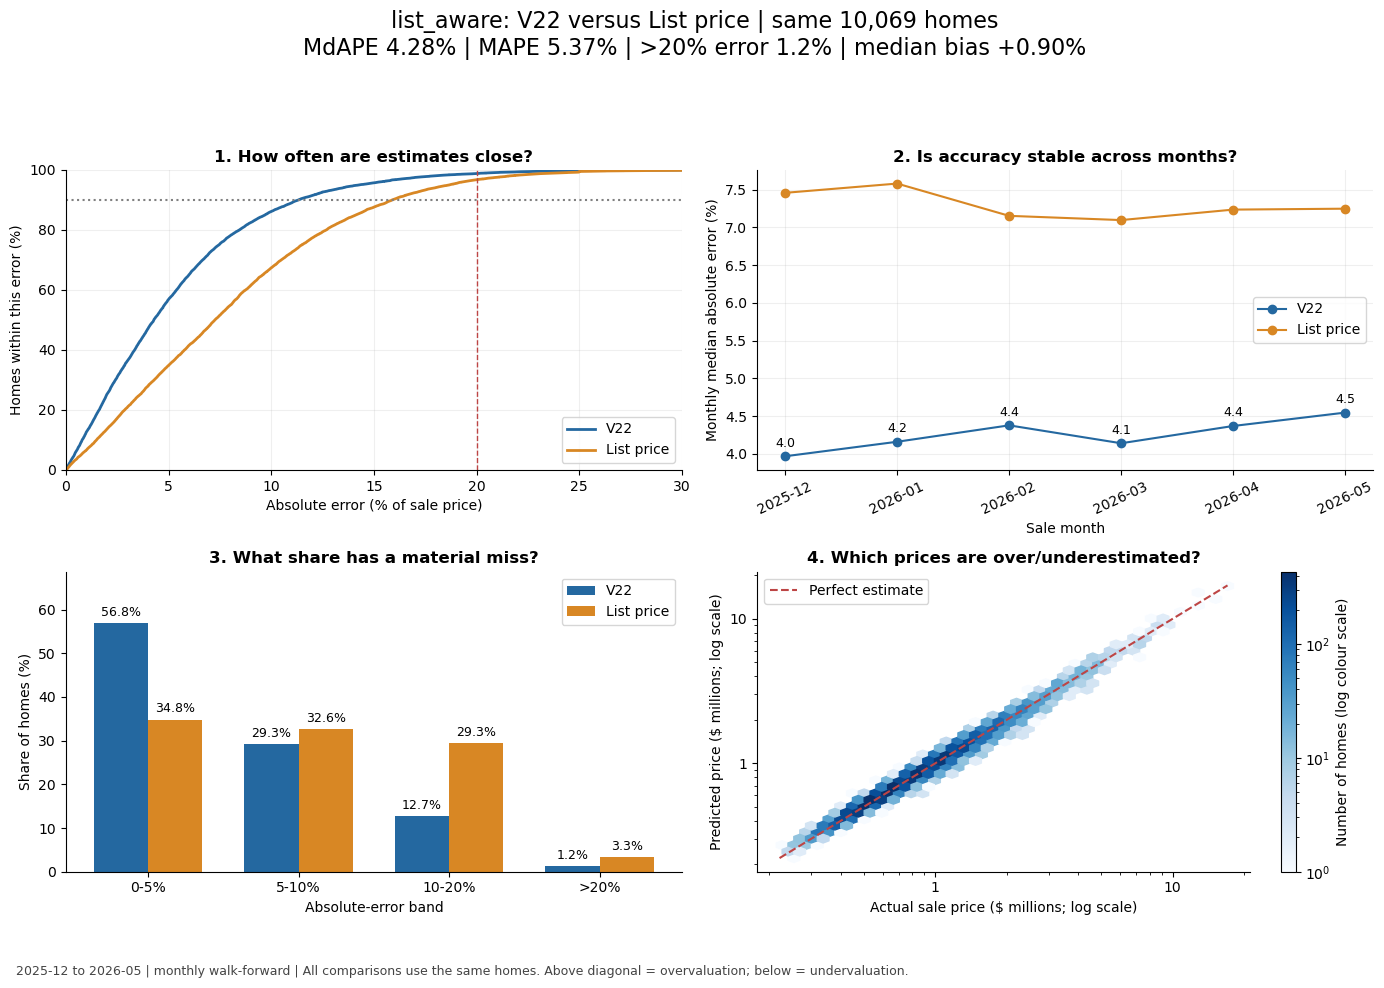

In [17]:
for track in ['off_market','list_aware']:
    overview(df.loc[df.track.eq(track)],OUT)

## 5. Both tracks: where errors concentrate

Each dashboard connects four questions: **which price ranges have large tail errors, which ranges are systematically over/undervalued, which property types have material misses, and which communities have the highest observed mean errors?** Baselines and group sample counts provide context.

Price bands use actual sale prices, so they explain failures after the event rather than providing a deployment warning. The eight-community ranking is exploratory and restricted to n >= 50; searching many communities can produce an unstable ranking. A plausible reason, such as unobserved luxury condition, remains a hypothesis until separately tested.

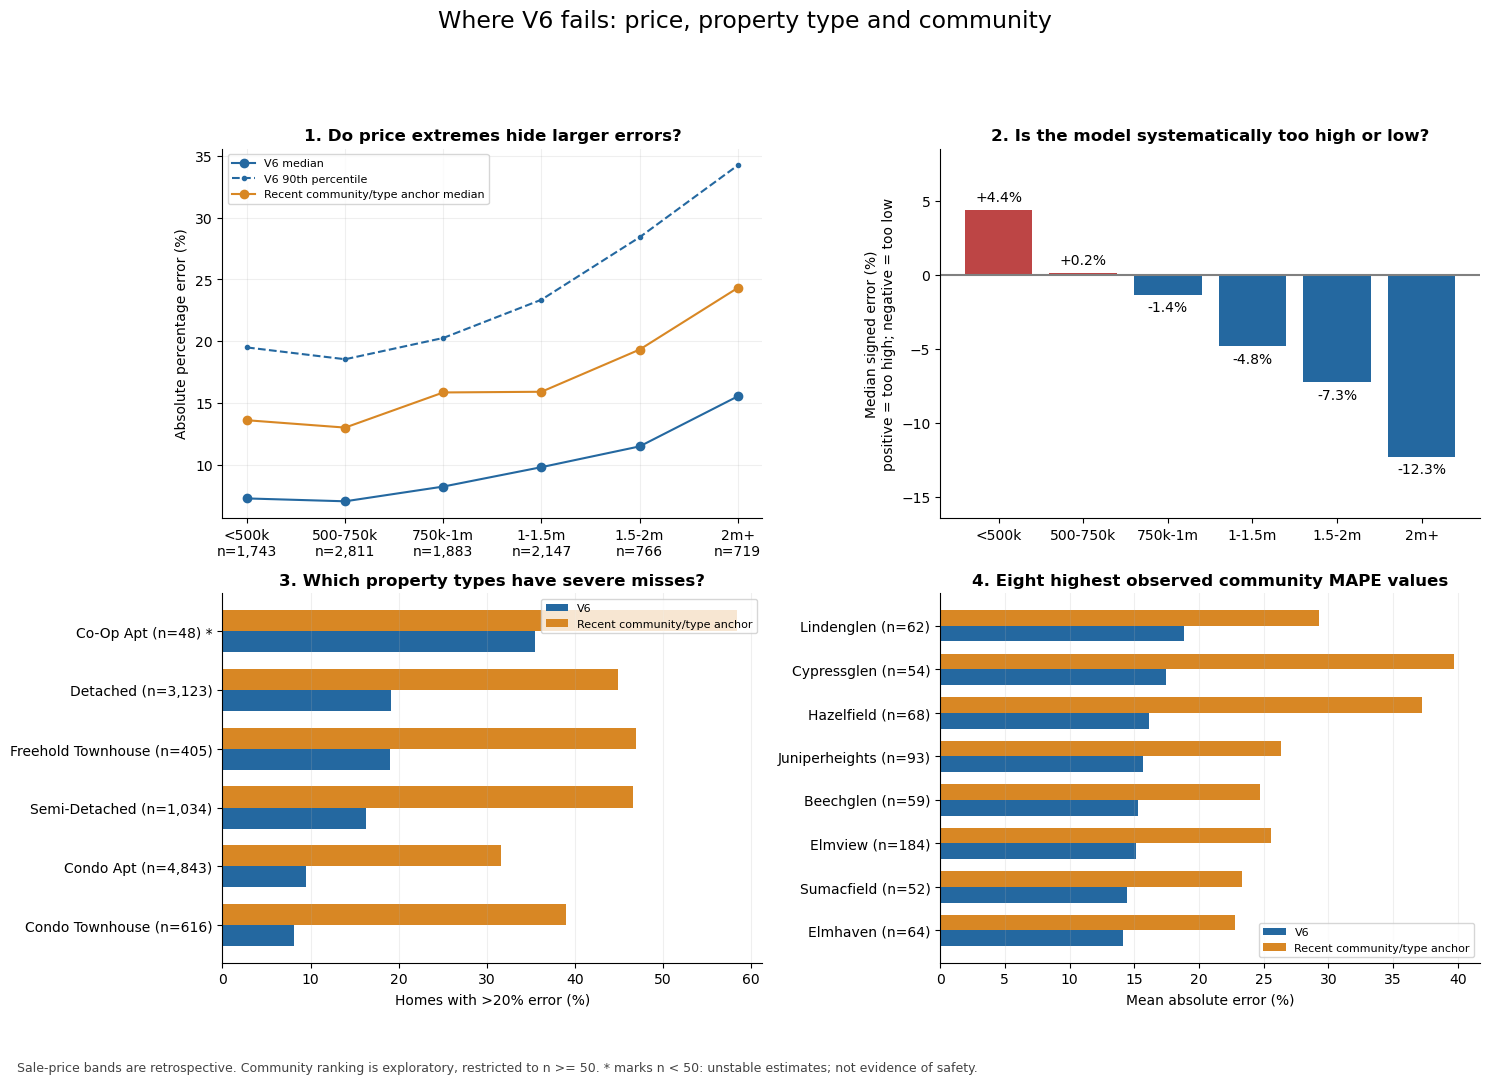

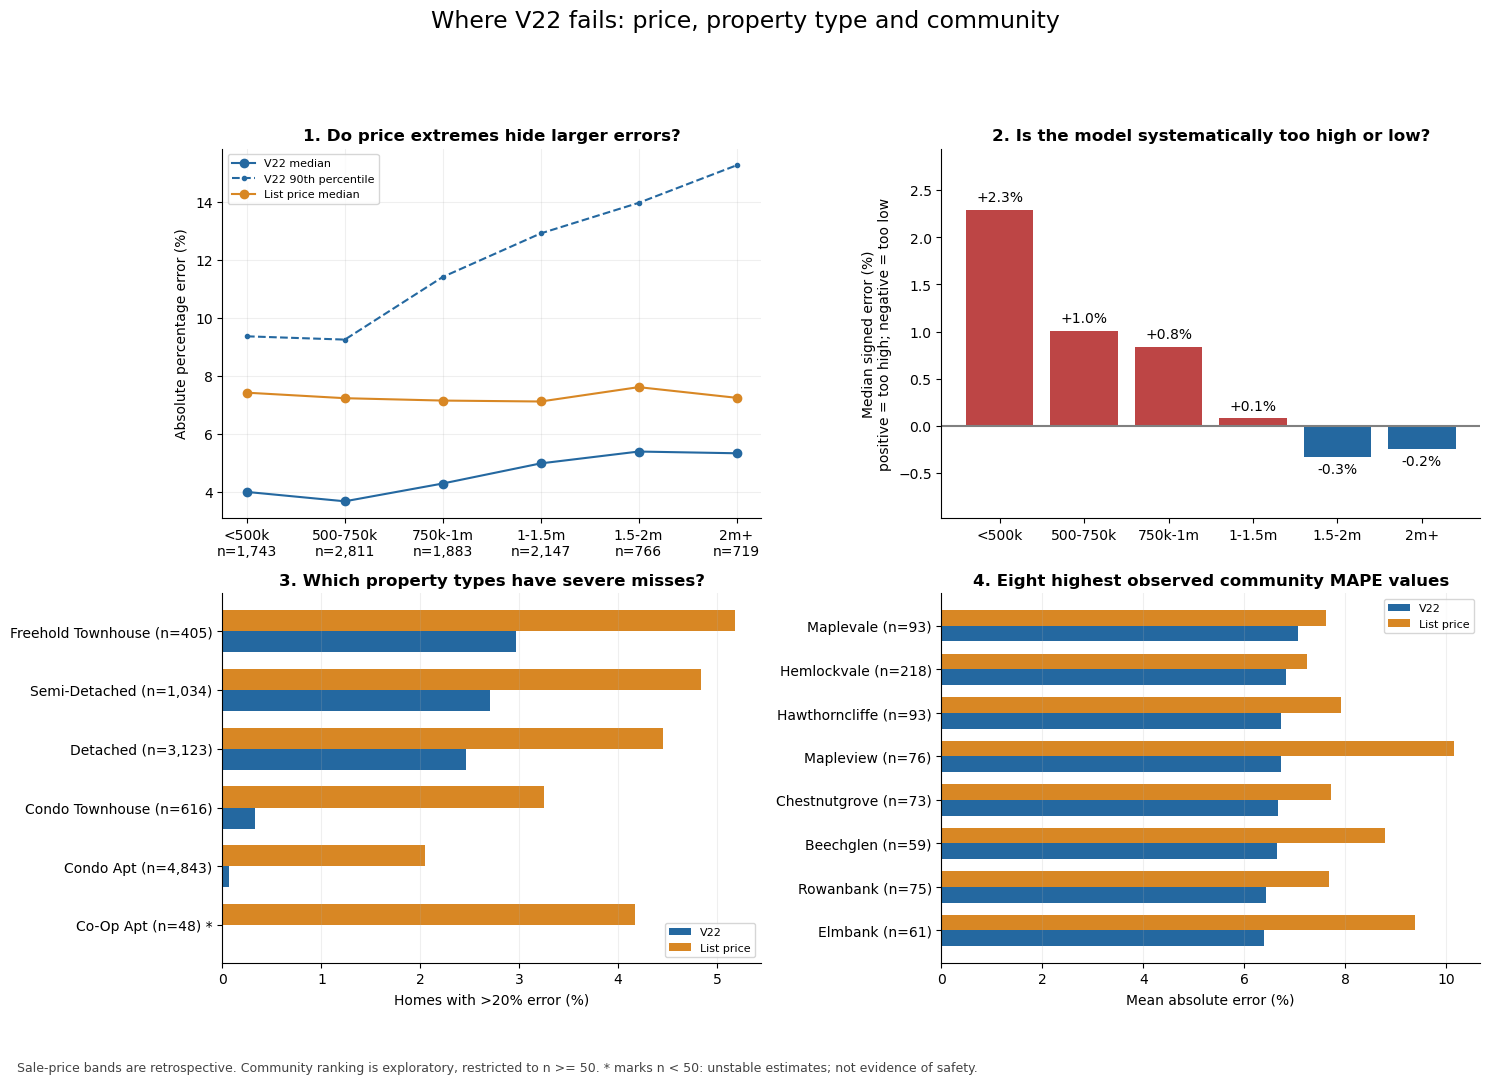

In [18]:
for track in ['off_market','list_aware']:
    failure_segments(df.loc[df.track.eq(track)],OUT)

## 6. V22 specifically: value added, harmful corrections and feature support

This is the key extra analysis for the final list-aware model.

1. **Sold versus ask:** does V22 improve on asking price when homes close well below or above it? This is retrospective explanation; the group definition already depends on the outcome.
2. **Historical peer ask:** does V22 help when asking $/sqft looks unusual compared with earlier sales? This uses the actual V22 feature, not a newly invented proxy. A positive gain means lower average APE than asking price; negative means the correction hurts.
3. **Recent discount support:** compare results when V22 has enough community sales, falls back to property type, or has no recent discount. This directly tests an important feature limitation.
4. **Rescued versus harmed:** counts homes whose asking-price error was >20% but V22 fixes it, and homes where V22 introduces a new >20% miss. An improved average does not mean every correction is helpful.

Paired tables also export gains by community, property type and month. They include win rate, new-large-miss rate and rescue rate, so we can acknowledge the model's harmful changes instead of reporting only improvements.

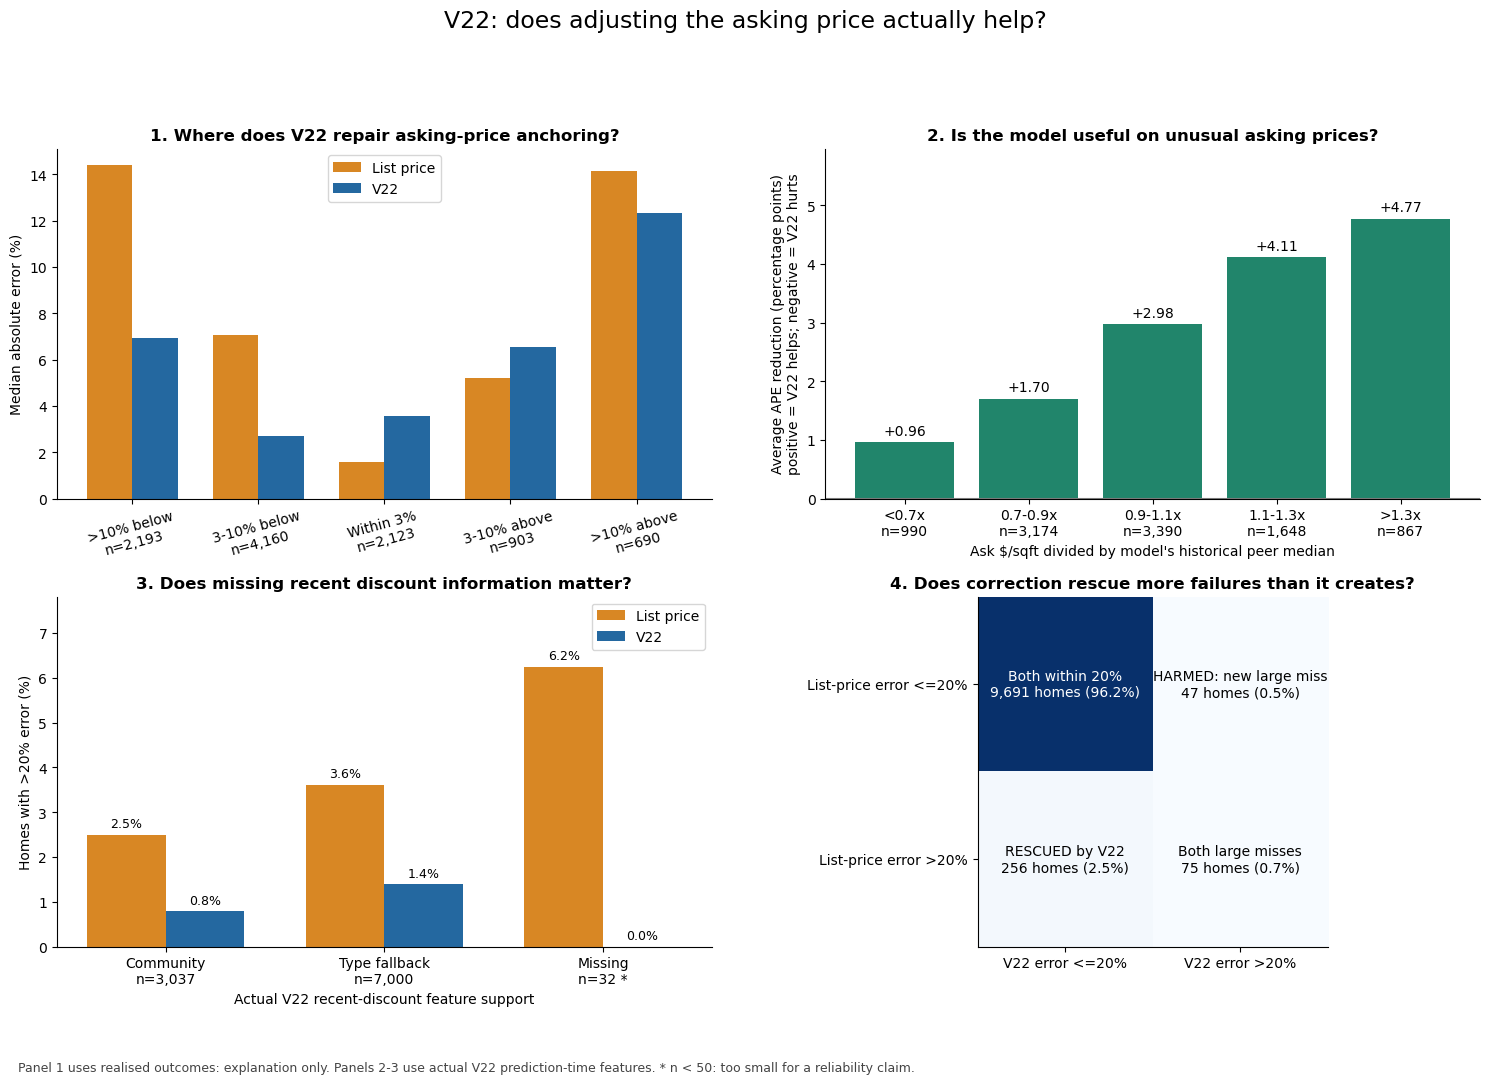

,n,V22_MdAPE,list_MdAPE,V22_MAPE,list_MAPE,mean_gain_pp,win_pct,rescued_n,harmed_n,still_large_n
0,10069,4.28,7.26,5.37,8.09,2.72,69.77,256,47,75


V22 weakest average gains: community (negative = worse than asking price)


,community,n,MdAPE,MAPE,baseline_MdAPE,baseline_MAPE,P90_APE,signed_median,over_20_pct,baseline_over_20_pct,mean_gain_pp,win_pct,harmed_into_failure_pct,rescued_from_failure_pct,small_sample
61,Hickoryglen,85,4.83,5.46,3.78,5.51,10.34,1.19,0.00,0.00,0.05,49.41,0.00,0.00,False
31,Sumacpark,114,3.57,4.35,3.85,4.51,8.90,1.05,0.00,0.00,0.16,54.39,0.00,0.00,False
126,Balsamcrest,72,5.01,5.90,4.95,6.28,10.61,0.95,1.39,2.78,0.38,62.50,0.00,1.39,False
23,Sycamoreglen,69,4.54,5.65,5.48,6.05,10.79,1.48,1.45,1.45,0.40,56.52,0.00,0.00,False
42,Hemlockvale,218,5.43,6.83,6.49,7.24,15.19,1.63,5.05,3.21,0.41,57.80,2.75,0.92,False
89,Maplevale,93,5.75,7.07,6.82,7.61,13.64,2.38,2.15,3.23,0.55,54.84,1.08,2.15,False
71,Lindenvale,54,5.19,6.00,5.06,6.59,13.31,0.64,0.00,1.85,0.59,44.44,0.00,1.85,False
103,Chestnutglen,53,4.35,6.11,5.48,6.75,13.56,0.02,1.89,3.77,0.64,60.38,0.00,1.89,False
78,Juniperheights,93,5.02,6.00,5.76,6.67,12.26,0.91,1.08,0.00,0.67,58.06,1.08,0.00,False
38,Juniperpark,62,5.24,5.94,5.28,6.61,11.06,1.51,0.00,0.00,0.67,56.45,0.00,0.00,False


V22 weakest average gains: house_type_name (negative = worse than asking price)


,house_type_name,n,MdAPE,MAPE,baseline_MdAPE,baseline_MAPE,P90_APE,signed_median,over_20_pct,baseline_over_20_pct,mean_gain_pp,win_pct,harmed_into_failure_pct,rescued_from_failure_pct,small_sample
2,Semi-Detached,1034,5.75,6.82,6.85,8.06,14.19,0.28,2.71,4.84,1.24,61.12,0.97,3.09,False
3,Freehold Townhouse,405,5.59,6.95,7.44,8.58,14.89,1.26,2.96,5.19,1.64,61.98,1.23,3.46,False
1,Detached,3123,5.42,6.61,7.57,8.49,13.91,1.27,2.47,4.45,1.88,64.94,0.96,2.95,False
4,Condo Townhouse,616,4.18,5.26,6.89,7.69,11.19,0.99,0.32,3.25,2.42,67.37,0.00,2.92,False
0,Condo Apt,4843,3.52,4.13,7.20,7.82,8.47,0.82,0.06,2.04,3.69,75.66,0.04,2.02,False


V22 weakest average gains: month (negative = worse than asking price)


,month,n,MdAPE,MAPE,baseline_MdAPE,baseline_MAPE,P90_APE,signed_median,over_20_pct,baseline_over_20_pct,mean_gain_pp,win_pct,harmed_into_failure_pct,rescued_from_failure_pct,small_sample
5,2026-05,2291,4.55,5.63,7.25,8.04,11.95,0.92,1.13,3.45,2.41,68.22,0.52,2.84,False
3,2026-03,1816,4.14,5.33,7.10,7.93,11.22,0.46,1.65,2.70,2.61,69.49,0.61,1.65,False
4,2026-04,2224,4.37,5.41,7.24,8.06,11.31,1.31,1.12,3.78,2.65,71.09,0.36,3.01,False
2,2026-02,1442,4.38,5.39,7.15,8.09,11.16,0.20,1.66,2.91,2.71,67.06,0.76,2.01,False
0,2025-12,1238,3.97,5.08,7.46,8.23,11.09,1.31,0.89,3.88,3.15,72.05,0.24,3.23,False
1,2026-01,1058,4.16,5.08,7.58,8.31,10.58,1.33,0.57,2.74,3.23,71.83,0.19,2.36,False


In [19]:
la = df.loc[df.model.eq('V22')].copy()
required=['v22_peer_ask','v22_discount_support','v22_peer_support']
assert set(required).issubset(la.columns), 'Rebuild final predictions to obtain actual V22 support diagnostics.'
v22_summary=v22_paired_analysis(la,OUT)
display(pd.DataFrame([v22_summary]).round(2))
for dim in ['community','house_type_name','month']:
    t=subgroup_table(la,dim)
    print('V22 weakest average gains:',dim,'(negative = worse than asking price)')
    display(t.loc[t.n.ge(MIN_N)].sort_values('mean_gain_pp').head(10).round(2))

## 7. Both tracks: can we identify danger before sale?

Warnings use sales closed before both the listing month and the model cutoff. They examine few recent local comparables, unusual same-type size, missing area, lack of an anchor, and (list-aware only) unusually high/low asking price versus a historical anchor. They are fixed heuristics, not fitted promises of safety.

The first panel compares material-error rates with/without each warning and shows the sample counts. The second is a 2x2 review table: **the unflagged-but-large-error cell is the failure of the warning system itself**. Read both the workload (share reviewed) and recall (share of large misses caught). These warning features use a conservative separate history; V22's actual feature support was analysed in section 6.

In [20]:
# Compute once per home/cutoff, then share across models. No off-market list-price input.
ref = listings.copy()
ref['square_feet'] = square_feet(ref['house_area'])
ref['psf'] = ref['sold_price'] / ref['square_feet'].where(ref['square_feet']>0)
queries = df[['ml_num','fit_cutoff','date_listed','community','house_type_name','square_feet']].drop_duplicates(['ml_num','fit_cutoff']).copy()
queries['history_end'] = queries[['fit_cutoff','date_listed']].min(axis=1).dt.to_period('M').dt.to_timestamp()
risk_parts=[]
for end, q in queries.groupby('history_end'):
    hist = ref.loc[(ref['date_sold']<end) & (ref['date_sold']>=end-pd.DateOffset(months=12))]
    local = hist.groupby(['community','house_type_name'], dropna=False).agg(local_n=('sold_price','size'), local_psf=('psf','median'))
    typical = hist.groupby('house_type_name').agg(type_psf=('psf','median'),
        area_low=('square_feet',lambda x:x.quantile(.01)), area_high=('square_feet',lambda x:x.quantile(.99)))
    z = q.merge(local.reset_index(),on=['community','house_type_name'],how='left').merge(typical.reset_index(),on='house_type_name',how='left')
    z['local_n'] = z['local_n'].fillna(0)
    z['sparse_comparables'] = z['local_n']<30
    seen = ref.loc[ref['date_sold']<end,'community']
    z['unseen_community'] = ~z['community'].isin(seen)
    z['anchor_psf'] = z['local_psf'].where(~z['sparse_comparables'],z['type_psf'])
    z['unusual_size'] = z['square_feet'].lt(z['area_low']) | z['square_feet'].gt(z['area_high'])
    risk_parts.append(z)
risk = pd.concat(risk_parts,ignore_index=True)
extra = ['ml_num','fit_cutoff','local_n','sparse_comparables','unseen_community','anchor_psf','unusual_size']
df = df.merge(risk[extra],on=['ml_num','fit_cutoff'],how='left',validate='many_to_one')
df['missing_area'] = df['square_feet'].isna() | df['square_feet'].le(0)
df['area_is_range'] = df['house_area'].astype(str).str.contains('-',regex=False)
df['no_anchor'] = ~np.isfinite(df['anchor_psf']) | df['anchor_psf'].le(0)
df['ask_vs_past_anchor'] = np.nan
mask = df['track'].eq('list_aware')
df.loc[mask,'ask_vs_past_anchor'] = df.loc[mask,'list_price'] / (df.loc[mask,'square_feet']*df.loc[mask,'anchor_psf'])
df['extreme_ask'] = mask & (df['ask_vs_past_anchor'].lt(.7) | df['ask_vs_past_anchor'].gt(1.3))
flags = ['sparse_comparables','unseen_community','unusual_size','missing_area','no_anchor','extreme_ask']
df['review_flag'] = df[flags].any(axis=1)
risk_tables=[]
for flag in flags + ['area_is_range','review_flag','listed_before_fit']:
    t = summarize(df,KEYS+[flag]); t['diagnostic']=flag
    t = t.rename(columns={flag:'flag_value'})
    risk_tables.append(t)
risk_table = pd.concat(risk_tables,ignore_index=True)
display(risk_table.round(2))
risk_table.to_csv(OUT/'observable_warning_metrics.csv',index=False)
review=[]
for key,g in df.groupby(KEYS,sort=False):
    bad=g['large_error']; flagged=g['review_flag']
    review.append({**dict(zip(KEYS,key)), 'review_share':flagged.mean(),
        'large_error_recall': (bad & flagged).sum()/bad.sum() if bad.any() else np.nan,
        'review_precision':bad[flagged].mean(), 'unflagged_large_error_rate':bad[~flagged].mean()})
review=pd.DataFrame(review)
display(review.round(3)); review.to_csv(OUT/'review_policy.csv',index=False)
print('Warnings can miss large errors. Unflagged does not mean safe. Validate any revised rule on a later untouched window.')

,track,model,protocol,source,flag_value,n,MdAPE,MAPE,P90_APE,over_20_pct,over_30_pct,median_signed_pct,median_abs_dollars,small_sample,diagnostic
0,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,False,8034,8.44,10.74,22.28,13.24,4.11,-1.05,61198.83,False,sparse_comparables
1,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,True,2035,9.20,11.42,23.07,14.89,4.57,-1.73,82254.41,False,sparse_comparables
2,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,False,8034,4.15,5.16,10.92,1.05,0.02,0.89,30289.80,False,sparse_comparables
3,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,True,2035,4.93,6.17,13.11,1.87,0.05,0.92,43938.81,False,sparse_comparables
4,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,False,10069,8.56,10.88,22.58,13.58,4.20,-1.23,64716.71,False,unseen_community
5,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,False,10069,4.28,5.37,11.33,1.21,0.03,0.90,32255.95,False,unseen_community
6,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,True,193,13.61,20.44,42.26,40.41,20.73,-3.96,134903.06,False,unusual_size
7,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,False,9876,8.50,10.69,22.06,13.05,3.88,-1.16,64280.29,False,unusual_size
8,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,True,193,3.88,5.01,10.90,0.52,0.00,0.56,33204.68,False,unusual_size
9,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,False,9876,4.29,5.37,11.33,1.23,0.03,0.91,32234.88,False,unusual_size


,track,model,protocol,source,review_share,large_error_recall,review_precision,unflagged_large_error_rate
0,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,0.218,0.268,0.167,0.127
1,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,0.369,0.508,0.017,0.009


Warnings can miss large errors. Unflagged does not mean safe. Validate any revised rule on a later untouched window.


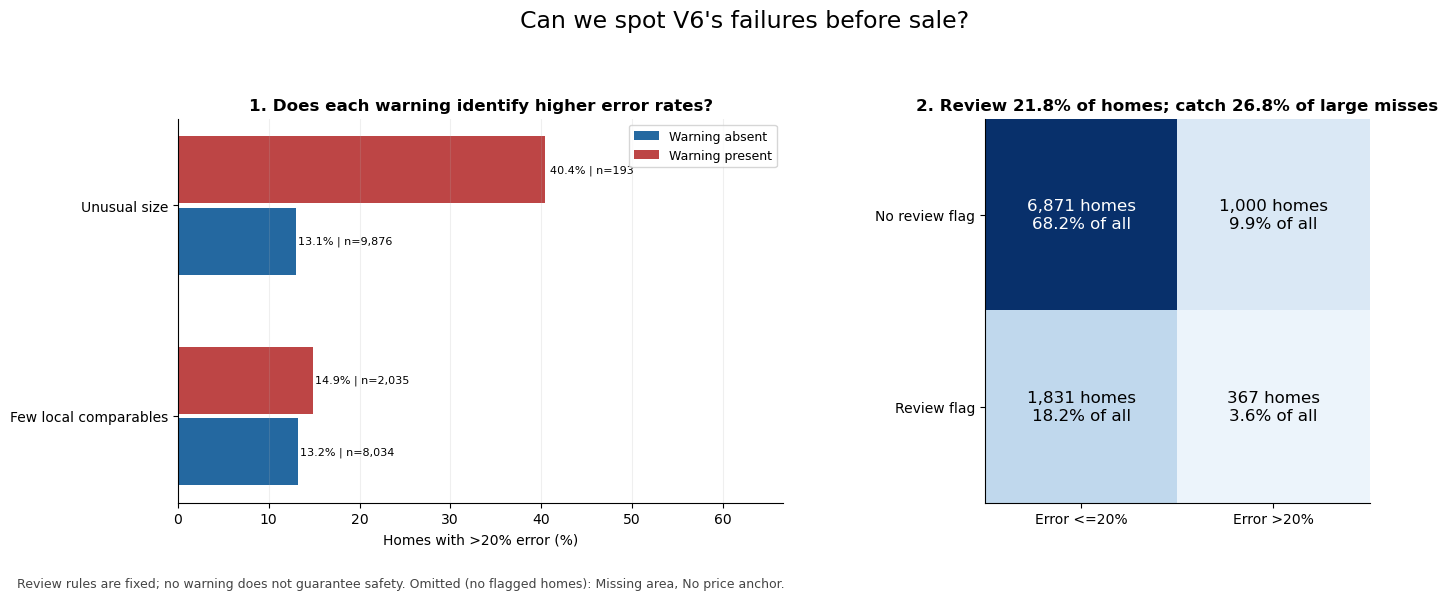

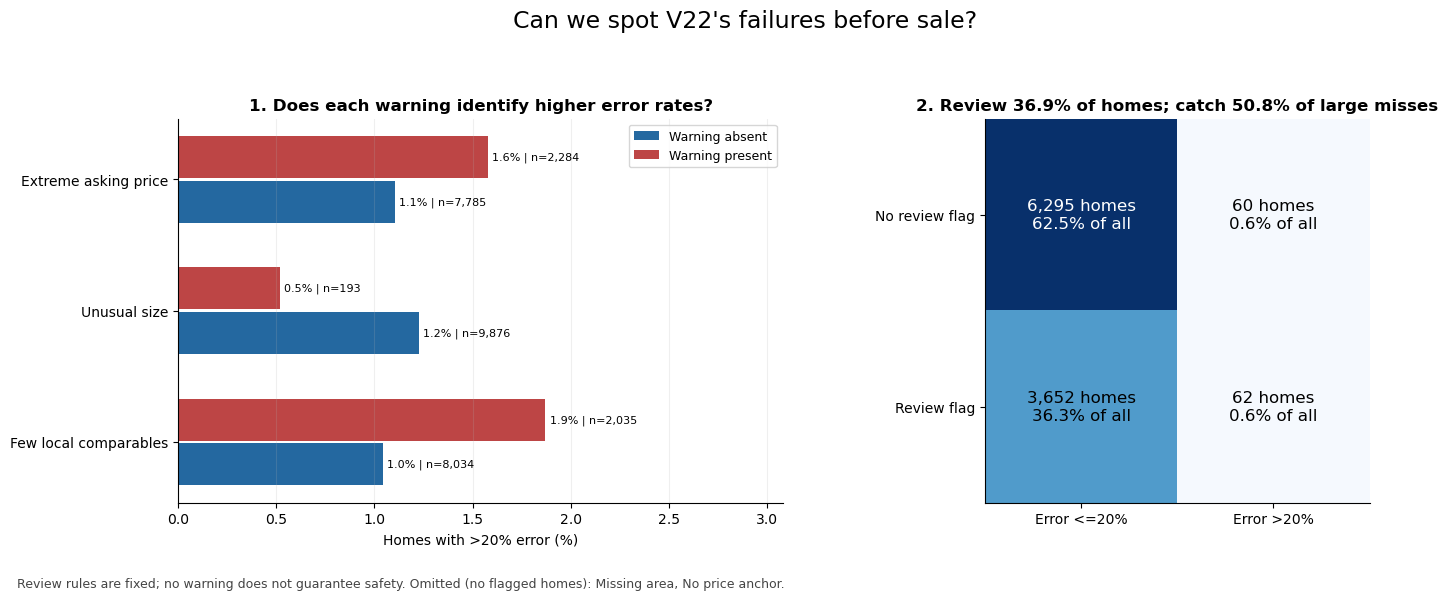

In [21]:
for track in ['off_market','list_aware']:
    warning_dashboard(df.loc[df.track.eq(track)],OUT)

## 8. Honest uncertainty and time limitations

Bootstrap whole sale months to preserve some shared market movement. With only six months, the 95% resampling ranges are exploratory; they are neither individual-home intervals nor a guarantee of hidden-test performance.

Some homes were listed before the model's training cutoff. This sale-month backtest matches the starter evaluation but does not prove strict performance at the original listing date. The flag does not itself establish leakage. Monthly refitting also differs from the June-September submission horizon, whose training data stop in May. A separate frozen four-month stress test is available below; do not merge its scores with monthly validation.

In [22]:
rng=np.random.default_rng(SEED)
uncertainty=[]
for key,g in df.groupby(KEYS,sort=False):
    blocks=[v['ape'].to_numpy() for _,v in g.groupby('month')]
    if len(blocks)<2: continue
    boot=[]
    for _ in range(400):
        sample=np.concatenate([blocks[i] for i in rng.integers(0,len(blocks),size=len(blocks))])
        boot.append([np.median(sample),np.mean(sample)])
    lo,hi=np.quantile(boot,[.025,.975],axis=0)
    uncertainty.append({**dict(zip(KEYS,key)), 'months':len(blocks),
        'MdAPE_lo':lo[0], 'MdAPE_hi':hi[0], 'MAPE_lo':lo[1], 'MAPE_hi':hi[1]})
uncertainty=pd.DataFrame(uncertainty)
display(uncertainty.round(2)); uncertainty.to_csv(OUT/'month_block_bootstrap.csv',index=False)

,track,model,protocol,source,months,MdAPE_lo,MdAPE_hi,MAPE_lo,MAPE_hi
0,off_market,V6,monthly_walk_forward,Source/data-verified final_models cache,6,8.44,8.71,10.70,11.08
1,list_aware,V22,monthly_walk_forward,Source/data-verified final_models cache,6,4.12,4.40,5.19,5.50


### Optional frozen-horizon stress test

Disabled by default because it trains additional models. Set `RUN_FROZEN_STRESS = True` to fit V6 and V22 once using sales before July 2025 and evaluate July-October without updates. Compare horizons within this same frozen experiment. Different calendar periods can have different difficulty, so the gap versus December-May is not purely an effect of staleness.

In [23]:
RUN_FROZEN_STRESS = False
if RUN_FROZEN_STRESS:
    stress=final_predictions(listings,protocol='frozen',start='2025-07',end='2025-10')
    stress['ape']=100*(stress.predicted_price/stress.sold_price-1).abs()
    table=stress.groupby(['model','month']).agg(n=('ml_num','size'),MdAPE=('ape','median'),MAPE=('ape','mean')).reset_index()
    display(table.round(2));table.to_csv(OUT/'frozen_four_month_stress.csv',index=False)
    fig,ax=plt.subplots(figsize=(9,4))
    for name,g in table.groupby('model'):ax.plot(g.month,g.MdAPE,marker='o',label=name)
    ax.set(title='Frozen July-cutoff stress test: no monthly updates',xlabel='Forecast month',ylabel='MdAPE (%)')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'frozen_stress.png',dpi=170);plt.show()

## 9. Individual cases: model failures and harmful adjustments

For each model, examine five worst errors and five near-median cases. V22 additionally shows the five largest deteriorations relative to asking price. The cases are deliberately selected, not representative. A text description does not establish property condition or explain an error causally. Off-market case tables omit asking price.

In [24]:
for track,g in df.groupby('track'):
    cols=['ml_num','month','house_type_name','community','sold_price','predicted_price','baseline_price',
          'ape','baseline_ape','gain_pp','signed_pct','square_feet','local_n','review_flag']
    if track=='list_aware':cols+=['list_price','v22_peer_ask','v22_discount_support']
    worst=g.nlargest(5,'ape').assign(case_selection='Worst model errors')
    typical=g.loc[(g.ape-g.ape.median()).abs().nsmallest(5).index].assign(case_selection='Near median model error')
    parts=[worst,typical]
    if track=='list_aware':parts.append(g.nsmallest(5,'gain_pp').assign(case_selection='Largest harm versus asking price'))
    cases=pd.concat(parts)
    print(g.model.iloc[0]);display(cases[cols+['case_selection']].round(2))
    cases[cols+['case_selection','remarks']].to_csv(OUT/f'{track}_cases.csv',index=False)

V22


,ml_num,month,house_type_name,community,sold_price,predicted_price,baseline_price,ape,baseline_ape,gain_pp,signed_pct,square_feet,local_n,review_flag,list_price,v22_peer_ask,v22_discount_support,case_selection
13367,SYN-0093108,2026-04,Detached,Dogwoodglen,450000.0,609506.34,492900.0,35.45,9.53,-25.91,35.45,999.5,38.0,True,492900.0,0.62,Type fallback,Worst model errors
10807,SYN-0142397,2026-03,Detached,Mapleview,2261000.0,1573979.75,1707500.0,30.39,24.48,-5.91,-30.39,1599.5,104.0,True,1707500.0,1.26,Type fallback,Worst model errors
1274,SYN-0103934,2025-12,Condo Townhouse,Hazelmills,890000.0,622556.10,639900.0,30.05,28.10,-1.95,-30.05,1654.0,20.0,True,639900.0,0.74,Type fallback,Worst model errors
2226,SYN-0057707,2025-12,Semi-Detached,Willowglen,594300.0,772500.91,693500.0,29.99,16.69,-13.29,29.99,1299.5,102.0,False,693500.0,0.67,Type fallback,Worst model errors
15194,SYN-0041089,2026-04,Detached,Rowanbrook,2305700.0,1621855.51,1684300.0,29.66,26.95,-2.71,-29.66,2175.0,22.0,True,1684300.0,0.88,Type fallback,Worst model errors
10272,SYN-0127765,2026-03,Semi-Detached,Willowview,865100.0,902162.56,863600.0,4.28,0.17,-4.11,4.28,1345.0,47.0,False,863600.0,0.89,Type fallback,Near median model error
18711,SYN-0020232,2026-05,Condo Apt,Mapleview,469700.0,489825.02,525100.0,4.28,11.79,7.51,4.28,473.0,84.0,False,525100.0,1.15,Type fallback,Near median model error
7061,SYN-0075513,2026-02,Semi-Detached,Rowanbank,837100.0,801242.70,779100.0,4.28,6.93,2.65,-4.28,1046.0,38.0,False,779100.0,0.82,Type fallback,Near median model error
1609,SYN-0044226,2025-12,Condo Apt,Cedarview,421200.0,403158.12,429500.0,4.28,1.97,-2.31,-4.28,748.0,303.0,False,429500.0,1.06,Community,Near median model error
1909,SYN-0028442,2025-12,Condo Apt,Elmmills,563700.0,539544.71,568300.0,4.29,0.82,-3.47,-4.29,1003.0,130.0,True,568300.0,1.20,Community,Near median model error


V6


,ml_num,month,house_type_name,community,sold_price,predicted_price,baseline_price,ape,baseline_ape,gain_pp,signed_pct,square_feet,local_n,review_flag,case_selection
17344,SYN-0031235,2026-05,Detached,Juniperheights,892200.0,2918631.73,2969497.18,227.13,232.83,5.70,227.13,1799.5,38.0,False,Worst model errors
7628,SYN-0138680,2026-03,Condo Apt,Tamarackmills,226200.0,738429.66,853040.61,226.45,277.12,50.67,226.45,1299.5,91.0,False,Worst model errors
8181,SYN-0083582,2026-03,Condo Apt,Rowanbrook,418100.0,926012.90,1093734.40,121.48,161.60,40.12,121.48,1299.5,222.0,False,Worst model errors
12382,SYN-0012460,2026-04,Semi-Detached,Lindenglen,2227900.0,4918510.51,5649267.39,120.77,153.57,32.80,120.77,7499.5,18.0,True,Worst model errors
8932,SYN-0101164,2026-03,Condo Apt,Beechglen,551900.0,1191203.67,1731925.11,115.84,213.81,97.97,115.84,2096.0,41.0,True,Worst model errors
8653,SYN-0016842,2026-03,Condo Apt,Oakbourne,407000.0,441841.12,454461.15,8.56,11.66,3.10,8.56,699.5,217.0,False,Near median model error
5765,SYN-0095852,2026-02,Condo Apt,Cedarview,319200.0,346526.97,362160.46,8.56,13.46,4.90,8.56,755.0,304.0,False,Near median model error
12457,SYN-0154846,2026-04,Condo Apt,Junipergardens,756000.0,691302.70,566087.25,8.56,25.12,16.56,-8.56,733.0,133.0,False,Near median model error
16845,SYN-0149267,2026-05,Condo Apt,Cypressdale,470800.0,511128.14,538641.11,8.57,14.41,5.84,8.57,599.5,192.0,False,Near median model error
13176,SYN-0132273,2026-04,Condo Apt,Hickorybourne,712400.0,651370.98,573030.46,8.57,19.56,11.00,-8.57,689.0,265.0,False,Near median model error


## 10. Report-ready section and reproducible evidence

The generated section reports actual V6/V22 numbers, supported subgroup weaknesses, warning-system limitations, V22's rescued and harmed homes, and temporal uncertainty. It does not turn speculative mechanisms into established causes. Use the saved figures with their captions and keep model names, evaluation dates and protocol in the report.

In [25]:
lines=['# Where the Model Fails: final V6 and V22','',
       'December 2025-May 2026 monthly walk-forward validation; final model choices fixed.']
for track,g in df.groupby('track'):
    m=metrics(g)
    lines += [f'## {track}: {g.model.iloc[0]}',
        f"n={len(g):,}; MdAPE {m['MdAPE']:.2f}%, MAPE {m['MAPE']:.2f}%, P90 APE {m['P90_APE']:.2f}%; "
        f"{m['over_20_pct']:.1f}% miss by more than 20%. Median signed error {m['median_signed_pct']:+.2f}%.",
        f"Matched baseline ({g.baseline_name.iloc[0]}) MdAPE {g.baseline_ape.median():.2f}%. "
        f"The model is closer on {100*g.gain_pp.gt(1e-8).mean():.1f}% of homes."]
    for dim in ['price_band','house_type_name','community']:
        t=subgroup_table(g,dim);t=t.loc[t.n.ge(MIN_N)]
        if len(t):
            w=t.sort_values('MAPE',ascending=False).iloc[0]
            lines.append(f"Highest observed {dim} MAPE among groups with n >= {MIN_N}: {w[dim]} "
                f"(n={int(w['n'])}; MdAPE {w['MdAPE']:.2f}%, MAPE {w['MAPE']:.2f}%, median signed error {w['signed_median']:+.2f}%). Exploratory finding.")
    flag=g.review_flag;bad=g.large_error
    recall=100*(flag&bad).sum()/bad.sum() if bad.any() else 0
    lines.append(f"Warnings flag {100*flag.mean():.1f}% of homes and capture {recall:.1f}% of large misses. "
                 f"Unflagged homes still have a {100*bad[~flag].mean():.1f}% large-error rate.")
    for number,label in [('01','overview'),('02','failure_segments'),('03','warning_effectiveness')]:
        lines.append(f'![{track} {label}]({track}_{number}_{label}.png)')
lines += ['## V22: incremental value and harmful corrections',
    f"V22 repairs {v22_summary['rescued_n']:,} homes whose asking-price error exceeds 20%, "
    f"but introduces {v22_summary['harmed_n']:,} new >20% misses; {v22_summary['still_large_n']:,} remain large misses under both.",
    '![V22 paired value](list_aware_04_V22_paired_value.png)',
    '## Limits and use recommendations',
    'A point estimate and an absent warning are not guarantees. Review unusual homes and high-consequence decisions using earlier comparable sales.',
    'Sale-price and sold-to-list groupings are retrospective explanations. Actual V22 peer-ask and feature-support diagnostics are available before sale.',
    'The validation window has already been inspected during model development. These are exploratory results, not independent hidden-test estimates. Neighbourhood rankings and causal explanations require further validation.',
    'Monthly sale-cutoff validation differs from valuation at the original listing date and from a four-month forecast frozen in May. Bootstrap ranges from six months do not establish future-regime robustness or per-home coverage.',
    'All homes, neighbourhoods and descriptions are synthetic; transfer to real Toronto homes is unproven.']
text='\n\n'.join(lines)
(OUT/'report_section.md').write_text(text,encoding='utf-8')
display(Markdown(text))
for track,g in df.groupby('track'):
    cols=['track','model','protocol','ml_num','fit_cutoff','month','sold_price','predicted_price','baseline_price',
          'ape','baseline_ape','gain_pp','signed_pct','house_type_name','community','price_band','local_n','review_flag']
    if track=='list_aware':cols+=['list_price','v22_peer_ask','v22_discount_support','v22_peer_support']
    g[cols].to_csv(OUT/f'{track}_audited_errors.csv',index=False)
print('Saved final-model figures (PNG/SVG), paired tables, cases and report to',OUT)

# Where the Model Fails: final V6 and V22



December 2025-May 2026 monthly walk-forward validation; final model choices fixed.

## list_aware: V22

n=10,069; MdAPE 4.28%, MAPE 5.37%, P90 APE 11.33%; 1.2% miss by more than 20%. Median signed error +0.90%.

Matched baseline (List price) MdAPE 7.26%. The model is closer on 69.8% of homes.

Highest observed price_band MAPE among groups with n >= 50: 2m+ (n=719; MdAPE 5.34%, MAPE 6.93%, median signed error -0.24%). Exploratory finding.

Highest observed house_type_name MAPE among groups with n >= 50: Freehold Townhouse (n=405; MdAPE 5.59%, MAPE 6.95%, median signed error +1.26%). Exploratory finding.

Highest observed community MAPE among groups with n >= 50: Maplevale (n=93; MdAPE 5.75%, MAPE 7.07%, median signed error +2.38%). Exploratory finding.

Warnings flag 36.9% of homes and capture 50.8% of large misses. Unflagged homes still have a 0.9% large-error rate.

![list_aware overview](list_aware_01_overview.png)

![list_aware failure_segments](list_aware_02_failure_segments.png)

![list_aware warning_effectiveness](list_aware_03_warning_effectiveness.png)

## off_market: V6

n=10,069; MdAPE 8.56%, MAPE 10.88%, P90 APE 22.58%; 13.6% miss by more than 20%. Median signed error -1.23%.

Matched baseline (Recent community/type anchor) MdAPE 15.33%. The model is closer on 71.7% of homes.

Highest observed price_band MAPE among groups with n >= 50: 2m+ (n=719; MdAPE 15.53%, MAPE 17.77%, median signed error -12.27%). Exploratory finding.

Highest observed house_type_name MAPE among groups with n >= 50: Detached (n=3123; MdAPE 10.07%, MAPE 12.51%, median signed error -2.46%). Exploratory finding.

Highest observed community MAPE among groups with n >= 50: Lindenglen (n=62; MdAPE 14.03%, MAPE 18.86%, median signed error +4.09%). Exploratory finding.

Warnings flag 21.8% of homes and capture 26.8% of large misses. Unflagged homes still have a 12.7% large-error rate.

![off_market overview](off_market_01_overview.png)

![off_market failure_segments](off_market_02_failure_segments.png)

![off_market warning_effectiveness](off_market_03_warning_effectiveness.png)

## V22: incremental value and harmful corrections

V22 repairs 256 homes whose asking-price error exceeds 20%, but introduces 47 new >20% misses; 75 remain large misses under both.

![V22 paired value](list_aware_04_V22_paired_value.png)

## Limits and use recommendations

A point estimate and an absent warning are not guarantees. Review unusual homes and high-consequence decisions using earlier comparable sales.

Sale-price and sold-to-list groupings are retrospective explanations. Actual V22 peer-ask and feature-support diagnostics are available before sale.

The validation window has already been inspected during model development. These are exploratory results, not independent hidden-test estimates. Neighbourhood rankings and causal explanations require further validation.

Monthly sale-cutoff validation differs from valuation at the original listing date and from a four-month forecast frozen in May. Bootstrap ranges from six months do not establish future-regime robustness or per-home coverage.

All homes, neighbourhoods and descriptions are synthetic; transfer to real Toronto homes is unproven.

Saved final-model figures (PNG/SVG), paired tables, cases and report to C:\Users\Elowe\OneDrive\Desktop\SSU-Data-Dash\outputs\where_model_fails\final_v6_v22
